# 11 - Detection avec RF-DETR (Roboflow, Apache-2.0) : un transformer sans ancres ni NMS

RF-DETR est un DETR temps reel a dos DINOv2. Difference de fond avec les YOLO : chaque
"requete" du decodeur predit AU PLUS un objet, et l'appariement hongrois de l'entrainement
interdit les doublons. Il n'y a donc ni ancres ni suppression des non-maxima (NMS). Le dos
DINOv2 (auto-supervise sur 142 millions d'images) transfere bien vers des domaines eloignes de
COCO, et nano a large sont sous Apache-2.0 (pas la contrainte AGPL d'Ultralytics).

Ce que tu vois ici, ecrit dans les cellules :

- le jeu au format COCO attendu par la librairie (`train/ valid/ test/` + `_annotations.coco.json`) ;
- l'entrainement par la librairie (EMA, augmentations multi-echelles, AdamW avec un taux par couche) ;
- le post-traitement en numpy : sigmoide, top-k sur les couples (requete, classe), boites
  `cx, cy, w, h` normalisees -> coins ; c'est lui que le programme de production reproduit ;
- un export verifie robuste aux ex aequo.

ATTENTION, essai QUICK : les poids COCO de RF-DETR sont sur le stockage de Roboflow, inaccessible
depuis l'environnement ou ce notebook a ete execute. On part donc de poids ALEATOIRES pour une
epoque : la chaine est verifiee, la precision est nulle (un transformer sans pre-entrainement
n'apprend rien en une epoque). Avec Internet : `WEIGHTS = "weights/rf-detr-nano.pth"`
(`python tools/fetch_weights.py --rfdetr nano`).

Prerequis : extra `rfdetr` (`pip install "rfdetr[train]"`), `python tools/get_data/get_neu_det.py`.
Duree en mode QUICK sur 2 coeurs : environ 4 minutes (davantage si la machine est chargee).

**Le fil** (memes etapes que le cours et que `ETAPES.md`, a la racine de la toolbox) :

```
1 Imports et reglages -> 2 Importer -> 3 Cataloguer -> 4 Decouper
  -> 5 Pretraiter et 7 Charger par lots (ecrire le jeu au format COCO, que la librairie lira par lots)
  -> 6 Augmenter, 7 Charger par lots, 8 Modele, 9 Perte et optimiseur, 10 Entrainer
     (un seul appel : la librairie fait les cinq)
  -> 13 Predire -> 11 Evaluer -> 12 Sauvegarder et exporter -> 13 Predire (post-traitement numpy)
```

La prediction (13) vient avant l'evaluation (11) : on evalue le chemin de production.

## Etape 1 - Imports et reglages

Deux cellules : d'abord REGLAGES (tout ce qu'on change pour ses propres donnees est la, et
seulement la), puis les imports et la preparation (affichage, graine du hasard).

In [1]:
# REGLAGES : tout ce qu'on change pour ses propres donnees est ici.
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import torch  # PyTorch : calcul sur des tenseurs (tableaux de nombres, sur CPU ou GPU) et reseaux de neurones

QUICK = True  # True : essai court sur CPU (240 images, 1 epoque = 1 passage, sans poids pre-entraines) ; False : complet (GPU)

IMAGES_DIR = Path("data/raw/neu_det/IMAGES")  # dossier des images NEU-DET (photos de defauts de surface sur de l'acier, 6 classes)
# un XML Pascal VOC par image, de meme nom : il decrit les boites (rectangles) des defauts
ANNOTATIONS_DIR = Path("data/raw/neu_det/ANNOTATIONS")
COLOR = "gray"  # lecture en niveaux de gris (acier sans couleur) ; "rgb" pour des images en couleur
PREPROCESS = []  # pretraitements avant le reseau ([] = aucun) ; ex. [{"name": "clahe", "clip_limit": 2.0, "tile_grid": 8}]
MAX_IMAGES = 240 if QUICK else None  # mode QUICK : 240 images seulement pour aller vite ; None = toutes les images
VAL_FRACTION, TEST_FRACTION = 0.15, 0.15  # part des images pour la validation (reglages) et pour le test final (note de fin) : 15 % chacune
SEED = 42  # graine du hasard (= runtime.seed de la toolbox) : meme decoupage et meme entrainement que la recette

SIZE = "nano"  # taille du modele : nano | small | medium | base (Apache-2.0) ; large : licence a verifier (non prevu ici)
# poids pre-entraines sur COCO (grand jeu public) ; None = depart de zero (aucun telechargement)
WEIGHTS = None if QUICK else "weights/rf-detr-nano.pth"
# cote de l'image carree donnee au reseau, multiple de 64 ; NEU-DET fait 200 px : inutile de monter plus haut
RESOLUTION = 256 if QUICK else 384
EPOCHS = 1 if QUICK else 50  # nombre d'epoques : passages complets sur les images d'entrainement
BATCH_SIZE = 4  # lot (batch) : images traitees ensemble a chaque pas ; plus grand = plus rapide mais plus de memoire
# accumulation : on additionne les gradients de N lots avant de corriger ; lot effectif = BATCH_SIZE x N (16 conseille)
GRAD_ACCUM_STEPS = 1 if QUICK else 4
LR, LR_ENCODER = 1e-4, 1.5e-4  # taux d'apprentissage (taille des corrections) : decodeur, puis encodeur DINOv2 (le dos pre-entraine)
PATIENCE = 0 if QUICK else 10  # arret anticipe sur la mAP de validation apres ce nombre d'epoques sans progres (0 = desactive)

CONF_EVAL = 0.001  # score mini pour calculer la mAP (note globale de detection) : il lui faut presque toutes les boites
CONF_PREDICT = 0.25 if QUICK else 0.4  # score mini en usage reel
TOP_K = 300  # nombre de couples (requete, classe) gardes, comme la librairie ; requete = une "case" du decodeur, 1 objet au plus
OPSET = 18  # version des operations ONNX (format standard de modele, executable sans PyTorch)

# calcul sur la carte graphique (GPU) si elle existe, sinon sur le processeur (CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = Path("outputs/notebooks/11_detection_rfdetr")  # dossier ou ce notebook ecrit ses resultats (poids, ONNX, carte du modele)
# decoupage ecrit par la recette (script de production) : sert a verifier qu'on utilise les memes images
RECIPE_SPLIT = Path("outputs/detection/quick_split.csv" if QUICK else "outputs/detection/neu_det_split.csv")
OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier de sortie (et ses parents) s'il n'existe pas encore
print("appareil :", DEVICE, "| mode", "QUICK" if QUICK else "complet")  # affiche ou tourne le calcul et le mode choisi

appareil : cpu | mode QUICK


In [2]:
import contextlib  # contextlib : outils pour les blocs "with" (ici, rediriger les affichages des librairies)
import io  # io : flux en memoire ; StringIO = un "faux fichier" texte qui avale ce qu'on veut cacher
import json  # json : lire et ecrire du texte JSON (annotations COCO, carte du modele)
import logging  # logging : journaux des librairies (on baisse leur niveau de bavardage)
import platform  # platform : infos sur la machine (version de Python notee dans la carte)
import random  # random : tirages au hasard de Python (sa graine est fixee plus bas)
import shutil  # shutil : copier, deplacer, effacer des fichiers et des dossiers entiers
import time  # time : chronometre pour mesurer les durees
import warnings  # warnings : masquer des avertissements connus et sans danger
import xml.etree.ElementTree as ET  # ElementTree : lire les fichiers XML d'annotations
from collections import Counter  # Counter : compte les occurrences (classe la plus frequente d'une image)
from datetime import UTC, datetime  # datetime : date et heure ; UTC = heure universelle, la meme partout

import cv2  # OpenCV : lecture, ecriture et traitement d'images
import matplotlib.pyplot as plt  # matplotlib : tracer des courbes et afficher des images
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import pandas as pd  # pandas : tableaux de donnees (DataFrame), ici le catalogue des images
from IPython.display import clear_output  # clear_output : efface la sortie de la cellule (affichages encombrants de l'entrainement)
from sklearn.model_selection import train_test_split  # train_test_split : coupe une liste en deux parties tirees au hasard

from vtb import viz  # viz : affichage de la toolbox (grilles d'images, tableaux)

viz.setup_notebook(dpi=80, fmt="jpeg")  # reglage des figures : resolution moderee et format jpeg (notebook plus leger)
# masque les avertissements generaux des librairies (nombreux et sans consequence ici)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)  # FutureWarning : classes et fonctions annoncees obsoletes par les librairies
warnings.filterwarnings("ignore", category=torch.jit.TracerWarning)  # export : avertissements de tracage attendus (TracerWarning)
# pour chaque journal bavard (rfdetr et Lightning, le moteur d'entrainement)
for name in ("rfdetr", "rf-detr", "pytorch_lightning", "lightning", "lightning.pytorch", "lightning.fabric"):
    # seulement les erreurs ; sans poids, rf-detr previent qu'il ne charge pas DINOv2 : c'est voulu
    logging.getLogger(name).setLevel(logging.ERROR)

## Etapes 2 a 4 - Importer, cataloguer, decouper : annotations et decoupage (comme le notebook 08)

Memes fonctions et meme decoupage que les notebooks 08 a 10. Explications : notebook 08, etapes 2 a 4.

In [3]:
# extensions de fichier acceptees comme images (comparees en minuscules)
IMAGE_EXTENSIONS = {".bmp", ".jpg", ".jpeg", ".png", ".tif", ".tiff"}


def read_image(path, color="gray"):  # lit une image et la renvoie en gris (H, W) ou en couleur RGB (H, W, 3)
    # octets bruts du fichier puis decodage tel quel (marche aussi avec des accents dans le chemin)
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_UNCHANGED)
    if image is None:  # None = le fichier n'est pas une image lisible
        raise ValueError(f"image illisible : {path}")  # on arrete tout de suite avec un message clair
    if image.ndim == 3 and image.shape[2] == 4:  # image a 4 canaux : couleur + transparence (alpha)
        image = image[:, :, :3]  # on garde les 3 canaux de couleur, on jette la transparence
    if color == "gray":  # si on veut du gris
        # image couleur -> gris ; image deja grise : rendue telle quelle
        return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image
    # couleur : BGR (ordre d'OpenCV) -> RGB ; gris : canal recopie 3 fois
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if image.ndim == 3 else np.stack([image] * 3, axis=-1)


def to_three_channels(image):  # renvoie toujours une image a 3 canaux (le reseau attend 3 canaux)
    # deja 3 canaux : inchangee ; gris (2D) : on recopie le canal 3 fois
    return image if image.ndim == 3 else np.stack([image] * 3, axis=-1)


def read_voc(xml_path):  # lit un XML Pascal VOC ; renvoie largeur, hauteur, boites (n, 4) et noms de classes
    root = ET.parse(xml_path).getroot()  # ouvre le XML et prend sa balise racine <annotation>
    # taille de l'image notee dans le XML (float puis int : accepte "200.0")
    width, height = int(float(root.findtext("size/width"))), int(float(root.findtext("size/height")))
    boxes, labels = [], []  # listes a remplir : une boite et un nom de classe par objet
    for obj in root.iter("object"):  # pour chaque objet annote dans l'image
        b = obj.find("bndbox")  # la balise qui contient la boite englobante (bounding box)
        # coins haut-gauche (x1, y1) et bas-droit (x2, y2), en pixels
        x1, y1, x2, y2 = (float(b.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))
        # boite ramenee a l'interieur de l'image si elle deborde
        boxes.append([max(0.0, x1), max(0.0, y1), min(float(width), x2), min(float(height), y2)])
        labels.append(obj.findtext("name").strip())  # nom de la classe, sans espaces autour
    # reshape(-1, 4) : tableau (0, 4) meme sans objet, pour garder la meme forme
    return width, height, np.array(boxes, np.float32).reshape(-1, 4), labels


def main_label(labels):  # classe la plus frequente de l'image (sert a equilibrer le decoupage)
    return Counter(labels).most_common(1)[0][0] if labels else "background"  # aucune boite : "background" (fond, image sans defaut)


def holdout(index, labels, fraction, seed):  # tire au hasard une part `fraction` des images ; renvoie leurs index
    counts = labels.value_counts()  # nombre d'images par classe principale
    # stratifier (memes proportions de classes dans chaque part) si : 2 classes ou plus, 2 images mini par classe, assez de place
    ok = len(counts) > 1 and counts.min() >= 2 and fraction * len(labels) >= len(counts)
    # stratifie si possible ; "_" = la part gardee (inutile ici), "held" = la part mise de cote
    _, held = train_test_split(index, test_size=fraction, stratify=labels if ok else None, random_state=seed)
    return pd.Index(held)  # index pandas des images mises de cote


records = []  # une fiche par image : chemin, taille, boites, classes
# chaque fichier image du dossier (sous-dossiers compris), trie par nom
for image_path in sorted(p for p in IMAGES_DIR.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS):
    # son XML porte le meme nom (stem = nom sans extension)
    width, height, boxes, labels = read_voc(ANNOTATIONS_DIR / f"{image_path.stem}.xml")
    # range la fiche de l'image
    records.append({"path": str(image_path), "width": width, "height": height, "boxes": boxes, "labels": labels})
# liste triee des classes presentes : leur position donne leur numero
CLASS_NAMES = sorted({label for r in records for label in r["labels"]})
CLASS_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}  # nom de classe -> numero (0, 1, 2...), ce que le reseau manipule
by_path = {r["path"]: r for r in records}  # chemin -> fiche, pour retrouver une fiche vite

# tableau : une ligne par image avec sa classe principale
catalog = pd.DataFrame([{"path": r["path"], "label": main_label(r["labels"])} for r in records])
if MAX_IMAGES is not None and len(catalog) > MAX_IMAGES:  # si on limite le nombre d'images (mode QUICK)
    # tire MAX_IMAGES images au hasard (random_state=0 : toujours les memes), remises dans l'ordre
    catalog = catalog.sample(n=MAX_IMAGES, random_state=0).sort_values("path").reset_index(drop=True)
labels = catalog["label"].astype(str)  # classe principale de chaque image, en texte
catalog["split"] = "train"  # par defaut, chaque image va dans l'entrainement
catalog.loc[holdout(catalog.index, labels, TEST_FRACTION, SEED), "split"] = "test"  # 15 % des images mises de cote pour le test
rest = catalog[catalog["split"] == "train"]  # les images restantes
# 15 % du total pris dans le reste pour la validation (0.15 / 0.85 du reste)
catalog.loc[holdout(rest.index, labels[rest.index], VAL_FRACTION / (1 - TEST_FRACTION), SEED), "split"] = "val"
catalog.to_csv(OUT / "split.csv", index=False)  # sauvegarde le decoupage pour le relire ou le comparer
SPLIT_MATCHES_RECIPE = None  # None = pas de decoupage de recette a comparer
if RECIPE_SPLIT.exists():  # si la recette a deja ecrit son decoupage
    # on le lit (keep_default_na=False : aucun texte lu comme valeur manquante)
    recipe = pd.read_csv(RECIPE_SPLIT, keep_default_na=False)[["path", "split"]]
    # jointure par chemin : True si chaque image est dans la meme part (train/val/test) que dans la recette
    SPLIT_MATCHES_RECIPE = bool(catalog[["path", "split"]].merge(recipe, on="path", suffixes=("", "_r")).eval("split == split_r").all())
print("decoupage identique a la recette :", SPLIT_MATCHES_RECIPE)  # True attendu (None si la recette n'a pas encore tourne)
# liste des fiches de chaque part : train, val, test
subsets = {s: [by_path[p] for p in catalog.loc[catalog["split"] == s, "path"]] for s in ("train", "val", "test")}
print({s: len(v) for s, v in subsets.items()}, CLASS_NAMES)  # nombre d'images par part et liste des classes

decoupage identique a la recette : True
{'train': 168, 'val': 36, 'test': 36} ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


## Etapes 5 et 7 - Pretraiter et charger par lots : le jeu au format COCO de Roboflow

La librairie attend trois dossiers `train/`, `valid/`, `test/`, chacun avec ses images et un
`_annotations.coco.json` : `images` (id, fichier, taille), `annotations` (id, image_id,
category_id, `bbox = [x, y, largeur, hauteur]` en pixels, aire), `categories` (ici 0 a C - 1).
Les images sont ecrites APRES pretraitement (la meme fonction qu'en production), en 3 canaux,
et les boites mises a l'echelle de l'image pretraitee.

In [4]:
def preprocess(image, steps=PREPROCESS):  # applique les pretraitements choisis (ex. CLAHE) ; renvoie l'image modifiee
    for step in steps:  # pour chaque operation demandee, dans l'ordre
        params = {k: v for k, v in step.items() if k != "name"}  # ses parametres : tout sauf le nom
        if step["name"] == "clahe":  # CLAHE : egalisation de contraste par zones, fait ressortir les details fins
            grid = int(params.get("tile_grid", 8))  # l'image est decoupee en grid x grid tuiles (8 par defaut)
            # contraste limite par clip_limit pour ne pas amplifier le bruit
            image = cv2.createCLAHE(clipLimit=float(params.get("clip_limit", 2.0)), tileGridSize=(grid, grid)).apply(image)
        else:  # operation inconnue de ce notebook
            # on arrete avec un message clair
            raise ValueError(f"operation {step['name']} non ecrite dans ce notebook (catalogue : notebook 02)")
    return image  # image pretraitee, meme taille que l'entree


def write_image(path, image_rgb):  # ecrit une image RGB (ou grise) sur le disque ; ne renvoie rien
    bgr = cv2.cvtColor(to_three_channels(image_rgb), cv2.COLOR_RGB2BGR)  # 3 canaux, puis RGB -> BGR (l'ordre qu'OpenCV ecrit)
    # encode en memoire au format donne par l'extension (.png) ; ok = reussite (non verifiee ici)
    ok, buffer = cv2.imencode(Path(path).suffix, bgr)
    buffer.tofile(str(path))  # ecrit les octets dans le fichier (marche aussi avec des accents dans le chemin)


def write_coco_dataset(subsets, root):  # ecrit le jeu au format COCO de Roboflow (train/ valid/ test/) ; renvoie le dossier racine
    if root.exists():  # si le dossier existe deja
        shutil.rmtree(root)  # on l'efface : jamais de vieilles images melangees aux nouvelles
    # chaque part et le nom de dossier attendu par la librairie ("val" -> "valid")
    for subset, folder in (("train", "train"), ("val", "valid"), ("test", "test")):
        target = root / folder  # dossier de cette part
        target.mkdir(parents=True)  # le cree (et ses parents)
        images, annotations = [], []  # description COCO des images et des boites de cette part
        for k, record in enumerate(subsets[subset]):  # pour chaque image de la part, avec son numero k
            # lue, pretraitee, en 3 canaux (la meme chaine qu'en production)
            image = to_three_channels(preprocess(read_image(record["path"], COLOR)))
            # facteurs image pretraitee / image d'origine (1 sauf si le pretraitement redimensionne)
            sx, sy = image.shape[1] / record["width"], image.shape[0] / record["height"]
            name = f"{k:06d}_{Path(record['path']).stem}.png"  # nom unique : numero sur 6 chiffres + nom d'origine, en PNG (sans perte)
            write_image(target / name, image)  # ecrit l'image pretraitee
            # decrit l'image : numero, fichier, taille
            images.append({"id": k, "file_name": name, "width": image.shape[1], "height": image.shape[0]})
            for (x1, y1, x2, y2), label in zip(record["boxes"], record["labels"]):  # pour chaque boite vraie de l'image
                w, h = float(x2 - x1) * sx, float(y2 - y1) * sy  # largeur et hauteur, a l'echelle de l'image pretraitee
                annotations.append(  # ajoute la boite au format COCO
                    {  # une boite = un dictionnaire de champs
                        "id": len(annotations) + 1,  # numero unique de la boite (COCO commence a 1)
                        "image_id": k,  # image a laquelle elle appartient
                        "category_id": CLASS_INDEX[label],  # numero de sa classe (0 a C - 1)
                        # format COCO : coin haut-gauche, largeur, hauteur (pixels de l'image pretraitee)
                        "bbox": [float(x1) * sx, float(y1) * sy, w, h],
                        "area": w * h,  # aire (COCO s'en sert pour les tailles petit / moyen / grand)
                        "iscrowd": 0,  # 0 = objet isole (pas une foule groupee)
                    }
                )
        # liste des classes ; supercategory = famille commune (ici "defect")
        categories = [{"id": i, "name": n, "supercategory": "defect"} for i, n in enumerate(CLASS_NAMES)]
        (target / "_annotations.coco.json").write_text(  # ecrit le fichier d'annotations attendu par la librairie
            json.dumps({"images": images, "annotations": annotations, "categories": categories}),  # les trois listes, en texte JSON
            encoding="utf-8",  # encodage du fichier texte
        )
    return root  # dossier racine du jeu


dataset_dir = write_coco_dataset(subsets, OUT / "coco_dataset")  # ecrit le jeu (efface et refait a chaque execution)
coco = json.loads((dataset_dir / "train" / "_annotations.coco.json").read_text())  # relit les annotations d'entrainement pour verifier
# nombre d'images, de boites, et une boite d'exemple
print(len(coco["images"]), "images,", len(coco["annotations"]), "boites ; exemple :", coco["annotations"][0])

168 images, 402 boites ; exemple : {'id': 1, 'image_id': 0, 'category_id': 0, 'bbox': [1.0, 18.0, 129.0, 81.0], 'area': 10449.0, 'iscrowd': 0}


## Etapes 6 a 10 - D'augmenter a entrainer : entrainer RF-DETR

Un seul appel couvre cinq etapes du fil : augmenter (6), charger par lots (7), construire le
modele (8), perte et optimiseur (9), entrainer (10).

La librairie fait la boucle : AdamW avec un taux plus faible pour l'encodeur DINOv2 (`LR_ENCODER`)
que pour le decodeur, moyenne mobile des poids (EMA), augmentations multi-echelles, mAP de
validation a chaque epoque, meilleur point de controle (`checkpoint_best_total.pth`).
`augmentation_backend="torchvision"` : selon la version, le choix automatique peut tomber sur
kornia, qui demande un GPU.

In [5]:
import rfdetr  # rfdetr : la librairie RF-DETR de Roboflow (modele, entrainement, export)

# apres l'import (la librairie regle son niveau de journal a l'import) : seulement les erreurs
logging.getLogger("rf-detr").setLevel(logging.ERROR)

# classe de modele selon SIZE (dictionnaire taille -> classe, puis [SIZE] choisit la bonne)
model_class = {"nano": rfdetr.RFDETRNano, "small": rfdetr.RFDETRSmall, "medium": rfdetr.RFDETRMedium, "base": rfdetr.RFDETRBase}[SIZE]
random.seed(SEED)  # meme etat du hasard que la recette au moment de construire le modele (poids aleatoires ici)
np.random.seed(SEED)  # idem pour numpy
_ = torch.manual_seed(SEED)  # idem pour PyTorch
model = model_class(pretrain_weights=WEIGHTS, resolution=RESOLUTION)  # cree le modele : poids de depart (ou aucun) et resolution d'entree
run_dir = OUT / "rfdetr_run"  # dossier de travail de la librairie (points de controle, metriques)
start = time.perf_counter()  # chrono
log = io.StringIO()  # la librairie (Lightning) imprime beaucoup : tout part dans ce journal, garde pour le diagnostic
with contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):  # sorties normales et erreurs redirigees vers le journal
    model.train(  # la librairie fait toute la boucle d'entrainement
        dataset_dir=str(dataset_dir),  # dossier du jeu COCO
        output_dir=str(run_dir),  # dossier ou elle ecrit ses resultats
        epochs=EPOCHS,  # nombre d'epoques
        batch_size=BATCH_SIZE,  # images par lot
        grad_accum_steps=GRAD_ACCUM_STEPS,  # lots accumules avant chaque correction des poids
        lr=LR,  # taux d'apprentissage du decodeur
        lr_encoder=LR_ENCODER,  # taux d'apprentissage de l'encodeur DINOv2
        early_stopping=PATIENCE > 0,  # arret anticipe seulement si PATIENCE > 0
        early_stopping_patience=max(PATIENCE, 1),  # patience (au moins 1, valeur exigee meme si l'arret est desactive)
        num_workers=0,  # lecture dans le processus principal (simple et reproductible)
        device="cuda" if DEVICE.type == "cuda" else "cpu",  # appareil de calcul, sous forme de texte
        augmentation_backend="torchvision",  # augmentations par torchvision (kornia, l'autre choix, demande un GPU)
        tensorboard=False,  # pas de journal TensorBoard (outil de suivi graphique)
        progress_bar=None,  # pas de barre de progression
        seed=SEED,  # meme graine que la recette
    )
TRAIN_SECONDS = round(time.perf_counter() - start, 1)  # duree d'entrainement en secondes
clear_output()  # Lightning affiche aussi des tableaux (rich, widgets) : on efface et on ne garde que le resume ci-dessous
(OUT / "train_log.txt").write_text(log.getvalue(), encoding="utf-8")  # sauvegarde le journal dans un fichier texte
best_checkpoint = next(  # premier point de controle trouve, par ordre de preference
    run_dir / n  # chemin complet du fichier candidat
    for n in ("checkpoint_best_total.pth", "checkpoint_best_ema.pth", "checkpoint_best_regular.pth")  # meilleur total, EMA, puis brut
    if (run_dir / n).exists()  # seulement s'il existe (next() prend le premier ; EMA = moyenne mobile des poids)
)
shutil.copy2(best_checkpoint, OUT / "best.pt")  # copie sous le nom best.pt (copy2 garde aussi la date du fichier)
print(f"entrainement : {TRAIN_SECONDS} s ; point de controle : {best_checkpoint.name}")  # bilan
metrics_csv = run_dir / "metrics.csv"  # metriques par epoque ecrites par la librairie
if metrics_csv.exists():  # si le fichier existe
    history = pd.read_csv(metrics_csv).groupby("epoch").first().reset_index()  # une ligne d'entrainement et une de validation par epoque
    # affiche les colonnes utiles qui existent (perte d'entrainement, mAP de validation)
    print(history[[c for c in ("epoch", "train/loss", "val/mAP_50", "val/mAP_50_95", "val/ema_mAP_50") if c in history]])

entrainement : 192.6 s ; point de controle : checkpoint_best_total.pth
   epoch  train/loss  val/mAP_50  val/mAP_50_95  val/ema_mAP_50
0      0    21.24605    0.019021       0.005469        0.019021


## Etapes 11 et 13 - Evaluer et predire : predire par le chemin de production, evaluer, choisir le seuil

Le meilleur point de controle est recharge (`RFDETR.from_checkpoint`). `model.predict` prend une
image RGB et rend des detections deja dans le repere de cette image ; on ramene a l'image
d'origine. Pas de NMS : un DETR rend ses `TOP_K` meilleurs couples (requete, classe). Detail des
metriques : notebook 08, etape 11.

In [6]:
from pycocotools.coco import COCO  # pycocotools : calcul officiel de la mAP COCO ; COCO = la verite terrain
from pycocotools.cocoeval import COCOeval  # COCOeval : compare predictions et verite, calcule les precisions moyennes (AP)
from rfdetr import RFDETR  # RFDETR : classe generale, sait recharger un point de controle

# recharge notre propre point de controle (trust_checkpoint : on accepte de lire ce fichier)
model = RFDETR.from_checkpoint(str(OUT / "best.pt"), trust_checkpoint=True)


def predict_images(net, images, conf):  # predit des images deja pretraitees ; renvoie un tableau (n, 6) par image
    """Images pretraitees -> (n, 6) dans leur repere ; on retire l'eventuelle classe "sans objet" (indice C)."""
    out = []  # resultats par image
    for image in images:  # une image a la fois
        # predict : pretraitement, reseau et post-traitement de la librairie ; seuil de score conf
        found = net.predict(to_three_channels(image), threshold=conf)
        # colonnes x1 y1 x2 y2 score classe ; reshape garde la forme (0, 6) sans detection
        rows = np.column_stack([found.xyxy, found.confidence, found.class_id]).astype(np.float32).reshape(-1, 6)
        out.append(rows[rows[:, 5] < len(CLASS_NAMES)])  # retire la classe "sans objet" (indice C) si elle sort
    return out  # une entree par image


def predict_paths(net, paths, conf):  # predit des fichiers images ; renvoie les boites dans l'image d'origine
    out = []  # resultats par image
    for path in paths:  # une image a la fois
        original = read_image(path, COLOR)  # lecture
        image = preprocess(original)  # pretraitement
        rows = predict_images(net, [image], conf)[0]  # prediction ; [0] = le tableau de cette unique image
        rows[:, [0, 2]] *= original.shape[1] / image.shape[1]  # x : image pretraitee -> image d'origine
        rows[:, [1, 3]] *= original.shape[0] / image.shape[0]  # y : idem
        out.append(rows)  # range
    return out  # une entree par chemin, dans l'ordre


def coco_metrics(items, preds, class_names):  # renvoie mAP50, mAP50-95 et AP par classe (verite et predictions en pixels d'origine)
    index = {n: i for i, n in enumerate(class_names)}  # nom de classe -> numero
    images, annotations = [], []  # verite au format COCO : liste des images et liste des boites
    for image_id, record in enumerate(items):  # pour chaque image, avec son numero
        images.append({"id": image_id, "width": record["width"], "height": record["height"]})  # decrit l'image
        for (x1, y1, x2, y2), label in zip(record["boxes"], record["labels"]):  # pour chaque boite vraie de l'image
            w, h = float(x2 - x1), float(y2 - y1)  # largeur et hauteur de la boite
            annotations.append(  # ajoute la boite au format COCO
                {  # une boite = un dictionnaire de champs
                    "id": len(annotations) + 1,  # numero unique de la boite (COCO commence a 1)
                    "image_id": image_id,  # image a laquelle elle appartient
                    "category_id": index[label],  # numero de sa classe
                    "bbox": [float(x1), float(y1), w, h],  # format COCO : coin haut-gauche, largeur, hauteur
                    "area": w * h,  # aire (COCO s'en sert pour les tailles petit / moyen / grand)
                    "iscrowd": 0,  # 0 = objet isole (pas une foule groupee)
                }
            )
    results = [  # predictions au format COCO : une entree par boite predite
        {  # une prediction
            "image_id": i,  # image concernee
            "category_id": int(r[5]),  # classe predite
            "bbox": [float(r[0]), float(r[1]), float(r[2] - r[0]), float(r[3] - r[1])],  # x, y, largeur, hauteur
            "score": float(r[4]),  # score de confiance
        }
        for i, rows in enumerate(preds)  # pour chaque image et ses detections
        for r in rows  # pour chaque detection [x1 y1 x2 y2 score classe]
    ]
    if not results:  # aucune detection (modele encore nul)
        # tout a zero (pycocotools planterait sur une liste vide)
        return {"map50": 0.0, "map50_95": 0.0, "per_class": {n: {"ap50": 0.0, "ap50_95": 0.0} for n in class_names}}
    with contextlib.redirect_stdout(io.StringIO()):  # tout ce que pycocotools affiche part dans un faux fichier : sortie propre
        truth = COCO()  # objet verite terrain vide
        truth.dataset = {  # on le remplit a la main (au lieu de lire un fichier JSON)
            "images": images,  # les images
            "annotations": annotations,  # les boites vraies
            "categories": [{"id": i, "name": n} for i, n in enumerate(class_names)],  # les classes
        }
        truth.createIndex()  # construit les tables de recherche internes
        evaluator = COCOeval(truth, truth.loadRes(results), iouType="bbox")  # evaluation de boites (pas de masques)
        evaluator.evaluate()  # apparie predictions et verites (IoU = aire commune / aire de l'union), image par image
        evaluator.accumulate()  # construit les courbes precision-rappel
        evaluator.summarize()  # calcule les 12 chiffres resumes (evaluator.stats)
    # precision par (seuil IoU, rappel, classe) ; toutes tailles d'objets, 100 detections max
    precision = evaluator.eval["precision"][:, :, :, 0, -1]
    per_class = {}  # AP de chaque classe
    for k, class_id in enumerate(evaluator.params.catIds):  # pour chaque classe evaluee
        # -1 = pas de donnee : on l'ecarte ; at50 = seuil IoU 0.5 seul, valid = tous les seuils
        at50, valid = precision[0, :, k][precision[0, :, k] > -1], precision[:, :, k][precision[:, :, k] > -1]
        per_class[class_names[class_id]] = {  # AP de la classe
            "ap50": round(float(at50.mean()), 4) if at50.size else 0.0,  # AP a IoU 0.5 (boite juste si recouvrement >= 50 %)
            "ap50_95": round(float(valid.mean()), 4) if valid.size else 0.0,  # moyenne sur les seuils IoU 0.5 a 0.95 (plus exigeant)
        }
    # stats[0] = mAP50-95, stats[1] = mAP50
    return {"map50": float(evaluator.stats[1]), "map50_95": float(evaluator.stats[0]), "per_class": per_class}


def box_iou(a, b):  # IoU de deux boites [x1, y1, x2, y2] : aire commune / aire de l'union, entre 0 et 1
    # aire de l'intersection (0 si les boites ne se touchent pas)
    inter = max(0.0, min(a[2], b[2]) - max(a[0], b[0])) * max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter  # aire A + aire B - partie commune
    return float(inter / union) if union > 0 else 0.0  # 0 si les boites sont degenerees (aire nulle)


# compte bonnes et mauvaises detections a un seuil ; renvoie precision, rappel, F1
def operating_point(items, preds, class_names, conf, iou=0.5):
    counts = {n: {"tp": 0, "fp": 0, "fn": 0} for n in class_names}  # par classe : vrais positifs, faux positifs, faux negatifs
    flagged = n_defect = 0  # images a defaut signalees par le modele / images a defaut
    for record, rows in zip(items, preds):  # pour chaque image et ses detections
        kept = rows[rows[:, 4] >= conf]  # detections au-dessus du seuil
        if len(record["labels"]):  # l'image contient au moins un defaut
            n_defect, flagged = n_defect + 1, flagged + bool(len(kept))  # compte l'image, et si le modele y a signale quelque chose
        for k, name in enumerate(class_names):  # classe par classe
            truth = [b for b, label in zip(record["boxes"], record["labels"]) if label == name]  # boites vraies de cette classe
            mine = kept[kept[:, 5] == k]  # boites predites de cette classe
            used = [False] * len(truth)  # chaque boite vraie ne peut etre trouvee qu'une fois
            for row in mine[np.argsort(-mine[:, 4])]:  # predictions de la plus sure a la moins sure
                # IoU avec chaque boite vraie encore libre (-1 si deja prise)
                scores = [box_iou(row[:4], t) if not used[j] else -1.0 for j, t in enumerate(truth)]
                best_j = int(np.argmax(scores)) if scores else -1  # la vraie qui recouvre le mieux (-1 s'il n'y en a pas)
                if best_j >= 0 and scores[best_j] >= iou:  # recouvrement suffisant : bonne detection
                    used[best_j] = True  # cette vraie est prise
                    counts[name]["tp"] += 1  # vrai positif
                else:  # rien de libre ou recouvrement trop faible
                    counts[name]["fp"] += 1  # faux positif (fausse alarme)
            counts[name]["fn"] += used.count(False)  # vraies jamais trouvees = faux negatifs (defauts rates)

    def rates(c):  # precision, rappel et F1 a partir des comptes
        p = c["tp"] / (c["tp"] + c["fp"]) if c["tp"] + c["fp"] else 0.0  # precision : part des detections qui sont justes
        r = c["tp"] / (c["tp"] + c["fn"]) if c["tp"] + c["fn"] else 0.0  # rappel : part des vrais defauts trouves
        # F1 : moyenne harmonique de la precision et du rappel
        return {**c, "precision": round(p, 4), "recall": round(r, 4), "f1": round(2 * p * r / (p + r), 4) if p + r else 0.0}

    total = {k: sum(c[k] for c in counts.values()) for k in ("tp", "fp", "fn")}  # comptes toutes classes confondues
    return {  # resultat
        "conf": conf,  # seuil utilise
        "overall": rates(total),  # toutes classes
        "per_class": {n: rates(c) for n, c in counts.items()},  # classe par classe
        # part des images a defaut ou le modele signale au moins une boite
        "image_recall": round(flagged / n_defect, 4) if n_defect else None,
    }


# detections sur la validation (seuil tres bas : toutes les boites)
val_preds = predict_paths(model, [r["path"] for r in subsets["val"]], CONF_EVAL)
start = time.perf_counter()  # chrono
test_preds = predict_paths(model, [r["path"] for r in subsets["test"]], CONF_EVAL)  # detections sur le test
MS_PER_IMAGE = round(1000 * (time.perf_counter() - start) / len(test_preds), 1)  # temps moyen par image (lecture comprise), en ms
sweep = pd.DataFrame(  # balayage des seuils sur la VALIDATION : une ligne par seuil
    # seuils 0.05, 0.10, ..., 0.95 ; pour chacun precision, rappel, F1 toutes classes
    [{"conf": c, **operating_point(subsets["val"], val_preds, CLASS_NAMES, c)["overall"]} for c in np.round(np.arange(0.05, 0.96, 0.05), 2)]
)
# seuil du meilleur F1 (CONF_PREDICT si F1 nul partout)
CHOSEN_CONF = float(sweep.loc[sweep["f1"].idxmax(), "conf"]) if sweep["f1"].max() > 0 else CONF_PREDICT
test_metrics = coco_metrics(subsets["test"], test_preds, CLASS_NAMES)  # mAP sur le test
op_chosen = operating_point(subsets["test"], test_preds, CLASS_NAMES, CHOSEN_CONF)  # precision / rappel au seuil choisi
op_recipe = operating_point(subsets["test"], test_preds, CLASS_NAMES, CONF_PREDICT)  # et au seuil de la recette
# bilan sur le test
print(f"test : mAP50 {test_metrics['map50']:.3f} | mAP50-95 {test_metrics['map50_95']:.3f} | {MS_PER_IMAGE} ms / image")
# seuil retenu et resultats du test a ce seuil
print(f"seuil retenu : {CHOSEN_CONF} (meilleur F1 de validation, {CONF_PREDICT} si aucun vrai positif) -> test", op_chosen["overall"])
score_max = max((float(p[:, 4].max()) for p in test_preds if len(p)), default=0.0)  # plus haut score vu sur le test (0 si aucune detection)
# rappel : sans pre-entrainement, les scores restent bas
print(f"score maximal sur le test : {score_max:.3f} (poids aleatoires et une epoque : les scores restent bas)")

test : mAP50 0.002 | mAP50-95 0.001 | 114.8 ms / image
seuil retenu : 0.25 (meilleur F1 de validation, 0.25 si aucun vrai positif) -> test {'tp': 0, 'fp': 0, 'fn': 84, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}
score maximal sur le test : 0.046 (poids aleatoires et une epoque : les scores restent bas)


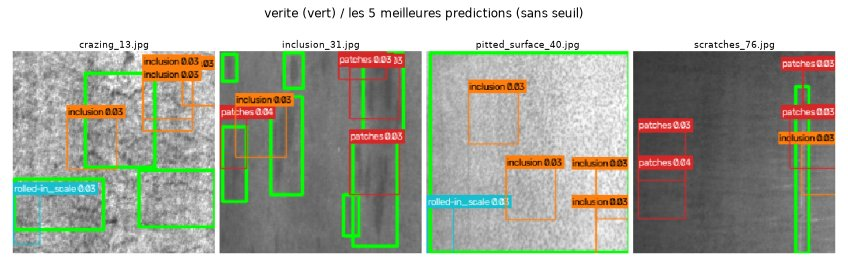

In [7]:
picked = [subsets["test"][i] for i in np.linspace(0, len(subsets["test"]) - 1, 4).astype(int)]  # 4 images de test reparties regulierement
pred_of = {r["path"]: p for r, p in zip(subsets["test"], test_preds)}  # chemin -> detections
viz.grid(  # grille d'images
    [  # une vignette dessinee par image choisie
        viz.draw_detections(  # dessine boites vraies et predites sur l'image
            read_image(r["path"], COLOR),  # image d'origine
            truth={"boxes": r["boxes"], "labels": [CLASS_INDEX[x] for x in r["labels"]]},  # verite terrain (boites et numeros de classe)
            pred={  # predictions : les 5 premieres lignes (la librairie les rend du meilleur score au moins bon)
                "boxes": pred_of[r["path"]][:5, :4],  # boites
                "labels": pred_of[r["path"]][:5, 5].astype(int),  # classes
                "scores": pred_of[r["path"]][:5, 4],  # scores
            },
            class_names=CLASS_NAMES,  # noms affiches
            conf=0.0,  # aucun seuil : on montre tout ce qui est passe
        )
        for r in picked  # pour chaque image choisie
    ],
    [Path(r["path"]).name for r in picked],  # titres : noms des fichiers
    ncols=4,  # 4 colonnes
    size=2.6,  # taille de chaque vignette
    suptitle="verite (vert) / les 5 meilleures predictions (sans seuil)",  # titre general
)
plt.show()  # affiche

## Etapes 12 et 13 - Exporter et predire : exporter en ONNX et ecrire le post-traitement

L'ONNX (lot fixe de 1) prend une image `RESOLUTION x RESOLUTION` et rend deux sorties :
`dets (1, Q, 4)` boites `cx, cy, w, h` NORMALISEES dans [0, 1] et `labels (1, Q, C + 1)` des
logits (le dernier indice ne sert pas). Le programme de production fait :

1. image pretraitee -> `/255` -> redimensionnement SANS garder les proportions (INTER_LINEAR,
   sur les flottants) -> normalisation ImageNet -> NCHW ;
2. sigmoide de chaque logit ; les `TOP_K` meilleurs couples (requete, classe) sur le tableau
   APLATI : `classe = indice % (C + 1)`, `requete = indice // (C + 1)` ;
3. garder `classe < C` et `score >= conf` ; boite de la requete x (largeur, hauteur) de l'image
   pretraitee ; PAS de NMS.

La verification compare la chaine ONNX + numpy a `model.predict` sur les 300 couples de chaque
image, en deux temps robustes aux ex aequo : les scores tries doivent coincider, et l'IoU n'est
mesure que sur les boites dont le score se distingue de tous les autres (entre deux requetes de
meme score, celle retenue au rang 300 depend d'un arrondi, ce n'est pas un defaut d'export).

In [8]:
import onnx  # onnx : lire et ecrire le format ONNX
import onnxruntime as ort  # onnxruntime : moteur qui execute un modele ONNX sans PyTorch


def rfdetr_input(image, resolution, mean, std):  # prepare l'entree ONNX d'une image ; renvoie un tableau (1, 3, R, R) float32
    """Image pretraitee (gris ou RGB) -> (1, 3, R, R) float32 : /255, redimensionnement sans proportions, mean/std."""
    # 3 canaux, en flottants entre 0 et 1 (division par 65535 en 16 bits, 255 sinon)
    x = to_three_channels(image).astype(np.float32) / (65535.0 if image.dtype == np.uint16 else 255.0)
    # redimensionnement a R x R SANS garder les proportions (l'image est etiree)
    x = cv2.resize(x, (resolution, resolution), interpolation=cv2.INTER_LINEAR)
    # normalisation : on retire la moyenne et on divise par l'ecart-type d'ImageNet, canal par canal
    x = (x - np.array(mean, np.float32)) / np.array(std, np.float32)
    # (H, W, C) -> (C, H, W), puis [None] ajoute l'axe du lot : NCHW
    return np.ascontiguousarray(x.transpose(2, 0, 1)[None], dtype=np.float32)


# post-traitement en numpy (celui de la production) ; renvoie (n, 6) dans l'image pretraitee
def postprocess_rfdetr(dets, logits, width, height, conf, top_k=TOP_K):
    """Sorties ONNX d'UNE image -> (n, 6) dans l'image pretraitee (largeur, hauteur)."""
    # sigmoide de chaque logit (score brut) -> probabilite entre 0 et 1 ; ravel aplatit (Q, C + 1) en une liste
    flat = (1.0 / (1.0 + np.exp(-logits.astype(np.float64)))).ravel()
    order = np.argsort(-flat, kind="stable")[:top_k]  # indices des top_k meilleurs scores ; tri "stable" : ex aequo dans un ordre fixe
    order = order[flat[order] >= conf]  # on garde ceux qui atteignent le seuil
    # indice aplati -> classe (reste de la division) et requete (quotient)
    classes, queries = order % logits.shape[1], order // logits.shape[1]
    keep = classes < len(CLASS_NAMES)  # la derniere classe (indice C) ne sert pas : on l'ecarte
    order, classes, queries = order[keep], classes[keep], queries[keep]  # on applique ce filtre aux trois tableaux
    b = dets[queries]  # boites (cx, cy, w, h normalisees) des requetes retenues
    # centre -/+ moitie de la taille = coins x1, y1, x2, y2 (encore normalises : fraction de la largeur / hauteur)
    corners = np.column_stack([b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2, b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2])
    # en pixels de l'image pretraitee, bornes a ses dimensions
    corners = (corners * [width, height, width, height]).clip(0, [width, height, width, height])
    return np.column_stack([corners, flat[order], classes]).astype(np.float32).reshape(-1, 6)  # colonnes x1 y1 x2 y2 score classe


def compare_detections(mine, reference, tie=1e-4):  # compare ONNX + numpy a la reference ; renvoie un bilan (dict)
    """Scores tries identiques ? IoU sur les boites a score distinct (les ex aequo s'ordonnent au hasard)."""
    gaps, ious = [0.0], []  # ecarts de scores (0.0 au depart : max() jamais vide) ; IoU des boites comparables
    for rows, ref in zip(mine, reference):  # image par image
        a, b = np.sort(rows[:, 4])[::-1], np.sort(ref[:, 4])[::-1]  # scores tries du plus grand au plus petit, des deux cotes
        if min(len(a), len(b)):  # si les deux cotes ont des boites
            # plus grand ecart entre scores de meme rang
            gaps.append(float(np.abs(a[: min(len(a), len(b))] - b[: min(len(a), len(b))]).max()))
        for k, row in enumerate(rows):  # pour chaque boite de notre chaine
            others = np.delete(rows[:, 4], k)  # les scores des autres boites
            # si son score n'a pas d'ex aequo (ecart > tie) et que la reference a des boites
            if len(ref) and (len(others) == 0 or np.abs(others - row[4]).min() > tie):
                # meilleur IoU avec une boite de la reference (1 si les coins sont a 0.5 px pres)
                ious.append(max(1.0 if np.allclose(row[:4], r[:4], atol=0.5) else box_iou(row[:4], r[:4]) for r in ref))
    return {  # bilan
        "boxes": int(sum(map(len, mine))),  # nombre de boites de notre chaine
        "reference_boxes": int(sum(map(len, reference))),  # nombre de boites de la reference
        "max_score_gap": max(gaps),  # plus grand ecart de score
        "distinct_boxes": len(ious),  # nombre de boites a score distinct comparees
        "mean_iou_distinct": float(np.mean(ious)) if ious else None,  # IoU moyen sur ces boites (None si aucune)
    }


resolution = model.model_config.resolution  # resolution d'entree reelle du modele
# moyenne et ecart-type de normalisation du modele, en nombres Python
mean, std = [float(v) for v in model.means], [float(v) for v in model.stds]
with contextlib.redirect_stdout(io.StringIO()):  # les messages de l'export sont avales
    exported = Path(  # chemin du fichier ONNX ecrit par la librairie
        model.export(  # export ONNX par la librairie
            output_dir=str(OUT / "rfdetr_export"),  # dossier temporaire
            shape=(resolution, resolution),  # entree carree R x R (lot fixe de 1)
            opset_version=max(17, min(OPSET, 18)),  # version des operations ONNX, bornee entre 17 et 18
            verbose=False,  # sans messages
        )
    )
onnx_path = OUT / "model.onnx"  # nom final du fichier ONNX
shutil.move(str(exported), onnx_path)  # deplace l'ONNX a sa place definitive
shutil.rmtree(OUT / "rfdetr_export", ignore_errors=True)  # efface le dossier temporaire (sans erreur s'il n'existe plus)
session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])  # charge l'ONNX dans onnxruntime, sur CPU
input_name = session.get_inputs()[0].name  # nom de l'entree du graphe
output_names = [o.name for o in session.get_outputs()]  # noms des sorties (boites, puis logits)
print("sorties ONNX :", [(o.name, o.shape) for o in session.get_outputs()])  # affiche nom et forme de chaque sortie

samples = [preprocess(read_image(r["path"], COLOR)) for r in subsets["val"][:4]]  # 4 images de validation pretraitees
mine, reference = [], []  # detections ONNX + numpy et detections de reference (model.predict)
for image in samples:  # pour chaque image
    dets, logits = session.run(None, {input_name: rfdetr_input(image, resolution, mean, std)})  # sorties ONNX : boites et logits
    # post-traitement numpy, sans seuil ; [0] retire l'axe du lot
    mine.append(postprocess_rfdetr(dets[0], logits[0], image.shape[1], image.shape[0], conf=0.0))
    reference.append(predict_images(model, [image], conf=0.0)[0])  # reference : la librairie, sans seuil
EXPORT_CHECK = compare_detections(mine, reference)  # comparaison robuste aux ex aequo
print(EXPORT_CHECK)  # affiche le bilan
# assert : arrete tout si c'est faux ; les scores tries doivent coincider a 0.001 pres
assert EXPORT_CHECK["max_score_gap"] <= 1e-3, "les scores ONNX + numpy different de model.predict"
# IoU moyen >= 0.98 exige sur les boites a score distinct
assert EXPORT_CHECK["mean_iou_distinct"] is None or EXPORT_CHECK["mean_iou_distinct"] >= 0.98


def timed(fn, runs=10):  # temps moyen d'un appel de fn, en millisecondes
    for _ in range(2):  # 2 appels d'echauffement (non chronometres)
        fn()  # appel a vide
    begin = time.perf_counter()  # debut du chrono
    for _ in range(runs):  # appels chronometres
        fn()  # appel mesure
    return round(1000 * (time.perf_counter() - begin) / runs, 2)  # duree moyenne en ms


x = rfdetr_input(samples[0], resolution, mean, std)  # entree ONNX d'une image, preparee une fois
LATENCY = {  # latence (temps d'une prediction) ; lambda = petite fonction sans nom
    # PyTorch par la librairie (pretraitement compris)
    "torch_cpu_ms": timed(lambda: model.predict(to_three_channels(samples[0]), threshold=0.5)),
    "onnxruntime_cpu_ms": timed(lambda: session.run(None, {input_name: x})),  # onnxruntime seul
}
print(LATENCY, "(torch : pretraitement compris)")  # temps par image : PyTorch contre onnxruntime

sorties ONNX : [('dets', [1, 300, 4]), ('labels', [1, 300, 7])]


{'boxes': 1200, 'reference_boxes': 1200, 'max_score_gap': 2.9802322387695312e-08, 'distinct_boxes': 41, 'mean_iou_distinct': 1.0}


{'torch_cpu_ms': 109.87, 'onnxruntime_cpu_ms': 96.37} (torch : pretraitement compris)


## Etape 12 - Sauvegarder et exporter : la carte du modele

`resize: stretch` (pas de letterbox), `mean / std` ImageNet, `dynamic_batch: false`, deux sorties.
Le prefixe `rfdetr:` choisit le decodeur top-k en production.

In [9]:
card = {  # carte du modele : tout ce qu'il faut pour l'utiliser sans ce notebook
    "task": "detection",  # type de tache
    "model_name": f"rfdetr:rfdetr_{SIZE}",  # le prefixe "rfdetr:" choisit le decodeur top-k en production
    "created_utc": datetime.now(UTC).strftime("%Y-%m-%dT%H:%M:%SZ"),  # date de creation (heure universelle)
    "framework": {  # versions des outils, pour reproduire
        "python": platform.python_version(),  # version de Python
        "torch": torch.__version__,  # version de PyTorch
        "onnx": onnx.__version__,  # version d'onnx
        "onnxruntime": ort.__version__,  # version d'onnxruntime
    },
    "input": {  # comment preparer l'entree
        "name": input_name,  # nom de l'entree du graphe
        "layout": "NCHW",  # ordre des axes : lot, canaux, hauteur, largeur
        "height": resolution,  # hauteur attendue
        "width": resolution,  # largeur attendue
        "channels": 3,  # 3 canaux
        "color": "RGB",  # ordre RGB
        "dtype": "float32",  # nombres a virgule sur 32 bits
        "scale": "divide by 255",  # valeurs divisees par 255 (0-1)
        "mean": mean,  # moyenne a soustraire (ImageNet)
        "std": std,  # ecart-type par lequel diviser (ImageNet)
        "resize": "stretch",  # image etiree a R x R (pas de letterbox)
        "letterbox_pad_value": None,  # pas de fond de remplissage
        "dynamic_batch": False,  # une image a la fois
        "read_color": COLOR,  # mode de lecture du fichier (gris ou couleur)
    },
    "preprocess": PREPROCESS,  # pretraitements a appliquer avant (ex. CLAHE)
    "outputs": [  # description des deux sorties
        {  # sortie 1
            "name": output_names[0],  # son nom
            "shape": [1, "queries", 4],  # (1, requetes, 4)
            "description": "boites cxcywh normalisees dans [0, 1] (par rapport a l'image recue)",  # ce qu'elle contient
        },
        {  # sortie 2
            "name": output_names[1],  # son nom
            "shape": [1, "queries", len(CLASS_NAMES) + 1],  # (1, requetes, classes + 1)
            "description": "logits par classe (le dernier indice ne sert pas)",  # ce qu'elle contient
        },
    ],
    "class_names": CLASS_NAMES,  # noms des classes, dans l'ordre des numeros
    "thresholds": {"conf": CHOSEN_CONF, "iou_nms": 0.6},  # seuils ; iou_nms n'est pas utilise par RF-DETR (pas de NMS)
    "postprocess": {  # comment decoder la sortie
        "steps": (  # etapes, en un long texte (les morceaux entre guillemets sont colles)
            "/255 (/65535 en 16 bits) -> redimensionner a resolution x resolution SANS garder les proportions (INTER_LINEAR) -> mean/std"
            " -> reseau -> sigmoide des logits -> 300 meilleurs couples (requete, classe) -> classe = indice % (C + 1)"
            " -> garder classe < C et score >= conf -> cxcywh x (largeur, hauteur) de l'image recue ; PAS de NMS"
        ),
        # code de reference
        "reference": "notebooks/11_detection_rfdetr (postprocess_rfdetr) ; vtb.tasks.detection.rfdetr_backend.postprocess_onnx",
    },
    "metrics": {  # performances sur le test
        "map50": test_metrics["map50"],  # mAP a IoU 0.5
        "map50_95": test_metrics["map50_95"],  # mAP moyenne sur IoU 0.5 a 0.95
        "n_images": len(subsets["test"]),  # nombre d'images de test
        "operating_point": op_chosen["overall"],  # precision / rappel / F1 au seuil choisi
    },
    "latency_ms": LATENCY,  # temps par image
    "files": {"onnx": "model.onnx"},  # fichier du modele, dans le meme dossier
    # origine des poids et trace de la verification d'export
    "notes": f"notebook 11 ; poids de depart : {WEIGHTS or 'aucun (aleatoires)'} ; verification ONNX : {EXPORT_CHECK}",
}
(OUT / "model_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")  # ecrit la carte en JSON lisible (indent=2)
print(json.dumps(card["input"], indent=1))  # affiche la partie "entree"

{
 "name": "input",
 "layout": "NCHW",
 "height": 256,
 "width": 256,
 "channels": 3,
 "color": "RGB",
 "dtype": "float32",
 "scale": "divide by 255",
 "mean": [
  0.485,
  0.456,
  0.406
 ],
 "std": [
  0.229,
  0.224,
  0.225
 ],
 "resize": "stretch",
 "letterbox_pad_value": null,
 "dynamic_batch": false,
 "read_color": "gray"
}


## Adapter a tes donnees

- Toujours partir des poids COCO (`WEIGHTS`) : sans eux, un transformer demande enormement de
  donnees et d'epoques. Sur un poste sans Internet : `tools/fetch_weights.py --rfdetr nano`
  ailleurs, puis copier `weights/`.
- `RESOLUTION` : multiple de 64, proche de la taille utile des defauts (384 par defaut pour nano).
- Lot effectif 16 (`BATCH_SIZE x GRAD_ACCUM_STEPS`) : sur un petit GPU, baisser `BATCH_SIZE` et
  monter `GRAD_ACCUM_STEPS`.

## Resultats

Poids aleatoires et une epoque : seuls comptent ici la chaine et la verification d'export.

In [10]:
recipe_file = Path("outputs/detection/quick_rfdetr/test_metrics.json")  # metriques ecrites par la recette quick_rfdetr
recipe = json.loads(recipe_file.read_text()) if QUICK and recipe_file.exists() else {}  # lues si disponibles (en mode QUICK seulement)
rows = {  # tableau de comparaison : une entree par source
    "notebook 11": {  # resultats de ce notebook
        "mAP50": test_metrics["map50"],  # mAP a IoU 0.5
        "mAP50-95": test_metrics["map50_95"],  # mAP sur IoU 0.5 a 0.95
        "entrainement (s)": TRAIN_SECONDS,  # duree d'entrainement
        "ecart de score export": EXPORT_CHECK["max_score_gap"],  # ecart de score ONNX / librairie
        "IoU export (scores distincts)": EXPORT_CHECK["mean_iou_distinct"],  # IoU moyen de la verification d'export
        "ONNX (ms)": LATENCY["onnxruntime_cpu_ms"],  # temps ONNX par image
    }
}
if recipe:  # si la recette a tourne
    rows["recette quick_rfdetr"] = {"mAP50": recipe["map50"], "mAP50-95": recipe["map50_95"]}  # ses resultats, pour comparer
viz.metrics_table(rows)  # affiche le tableau

,mAP50,mAP50-95,entrainement (s),ecart de score export,IoU export (scores distincts),ONNX (ms)
notebook 11,0.002,0.001,192.6,0.0,1.0,96.37
recette quick_rfdetr,0.002,0.001,NaN,NaN,NaN,NaN


## Passer en production

```
python recipes/detection/scripts/run.py --config recipes/detection/configs/quick_rfdetr.yaml
python -m vtb.serve --model outputs/notebooks/11_detection_rfdetr
```

Controle : `vtb.serve.predictor.OnnxPredictor` (sans PyTorch) relit le dossier exporte et doit
rendre les memes boites que la chaine ONNX + numpy de ce notebook.

In [11]:
# affiche le fichier de configuration de la recette correspondante
print(Path("recipes/detection/configs/quick_rfdetr.yaml" if QUICK else "recipes/detection/configs/rfdetr_nano_neudet.yaml").read_text())

# Verification rapide de la chaine RF-DETR nano (CPU) : memes 240 images NEU-DET que quick_yolo, 1 epoque, 256 px.
# weights: null = depart de zero (aucun telechargement) ; la chaine est verifiee, pas la precision.
data:
  root: data/raw/neu_det/IMAGES
  layout: annotations
  annotations_dir: data/raw/neu_det/ANNOTATIONS
  annotation_format: voc
  color: gray
  max_images: 240
split: {file: outputs/detection/quick_split.csv, strategy: stratified, val_fraction: 0.15, test_fraction: 0.15}
backend: rfdetr
rfdetr:
  size: nano
  weights: null                        # weights/rf-detr-nano.pth : poids COCO (tools/fetch_weights.py --rfdetr nano)
  resolution: 256                      # multiple de 64 ; 384 par defaut pour nano
  epochs: 1
  batch_size: 4
  grad_accum_steps: 1
  patience: 0
export: {openvino: true, latency_runs: 3}
runtime: {output_dir: outputs/detection/quick_rfdetr, num_workers: 0}



In [12]:
CONTROL_CONF = 0.0  # seuil 0 : toutes les detections du top-k, le plus de boites possible a comparer
from vtb.serve.predictor import OnnxPredictor  # noqa: E402 - la toolbox n'intervient qu'ici, pour le controle

predictor = OnnxPredictor(OUT)  # charge le dossier exporte (ONNX + carte), comme le fait le service


def notebook_rows(original, conf):  # chaine de ce notebook ; renvoie les boites (n, 6) dans l'image d'origine
    """La chaine de ce notebook, de l'image lue aux boites dans l'image d'origine."""
    image = preprocess(original)  # pretraitement
    dets, logits = session.run(None, {input_name: rfdetr_input(image, resolution, mean, std)})  # ONNX : boites et logits
    rows = postprocess_rfdetr(dets[0], logits[0], image.shape[1], image.shape[0], conf)  # post-traitement numpy ; [0] retire l'axe du lot
    # x -> image d'origine, bornes a la largeur de l'image
    rows[:, [0, 2]] = (rows[:, [0, 2]] * original.shape[1] / image.shape[1]).clip(0, original.shape[1])
    # y -> image d'origine, bornes a la hauteur
    rows[:, [1, 3]] = (rows[:, [1, 3]] * original.shape[0] / image.shape[0]).clip(0, original.shape[0])
    return rows  # detections


worst, compared = 0.0, 0  # plus grand ecart vu, nombre de boites comparees
for conf in (CHOSEN_CONF, CONTROL_CONF):  # le seuil de la carte, puis un seuil bas pour comparer beaucoup de boites
    predictor.card.thresholds["conf"] = conf  # le predicteur utilise ce seuil
    for r in subsets["test"][:10]:  # 10 images de test
        original = read_image(r["path"], COLOR)  # image d'origine
        rows, served = notebook_rows(original, conf), predictor(original)["objects"]  # boites du notebook et du predicteur de production
        # meme nombre de boites, sinon arret
        assert len(served) == len(rows), f"{Path(r['path']).name} : {len(served)} objets servis contre {len(rows)}"
        if len(rows):  # s'il y a des boites
            # plus grand ecart de coordonnee (memes boites, meme ordre)
            worst = max(worst, float(np.abs(np.array([o["box"] for o in served]) - rows[:, :4]).max()))
            compared += len(rows)  # compte les boites comparees
predictor.card.thresholds["conf"] = CHOSEN_CONF  # remet le seuil choisi
# bilan du controle
print(f"OnnxPredictor (production) == notebook : {compared} boites sur 10 images de test, ecart max {worst:.2f} px (arrondi a 0,1 px)")
assert worst <= 0.15  # ecart tolere : l'arrondi a 0.1 px du predicteur
print("decoupage identique a la recette :", SPLIT_MATCHES_RECIPE)  # rappel du controle du decoupage

OnnxPredictor (production) == notebook : 3000 boites sur 10 images de test, ecart max 0.05 px (arrondi a 0,1 px)
decoupage identique a la recette : True


## Pour aller plus loin

- Configuration complete (`QUICK = False`, poids COCO, 50 epoques) sur GPU : `prompts/03`.
- RF-DETR base (plus precis, plus lent) : `SIZE = "base"`, `RESOLUTION = 560`.
- Meme decoupage, autres moteurs : notebooks 08 (YOLO11), 09 (YOLOX), 10 (Faster R-CNN).

Menage : le jeu COCO et le dossier d'entrainement de la librairie (points de controle de plusieurs centaines de Mo) se regenerent a chaque execution ; on garde le modele (`best.pt`),
`model.onnx`, la carte du modele et les decoupages.

In [13]:
for folder in ("coco_dataset", "rfdetr_run"):  # dossiers lourds, regeneres a chaque execution
    shutil.rmtree(OUT / folder, ignore_errors=True)  # efface le dossier (sans erreur s'il n'existe pas)
print(sorted(p.name for p in OUT.iterdir()))  # ce qui reste dans le dossier de sortie

['best.pt', 'model.onnx', 'model_card.json', 'split.csv', 'train_log.txt']
